# 11 — Preprocessing rs-fMRI: dari *Time Series* DCAN sampai FC Tangent

Notebook ini menjelaskan, langkah demi langkah, bagaimana *time series* rs-fMRI setiap subjek diubah menjadi **fitur konektivitas fungsional (FC)** yang dipakai skenario S1–S4 dan baseline Logistic Regression.

| | |
| :--- | :--- |
| **Masukan** | `data/processed/kohort_dcan.csv` (1.638 subjek, notebook 09) · *time series* DCAN 3 atlas + masker gerakan setiap subjek (`data/raw_dcan/`) |
| **Keluaran** (sudah dibuat oleh notebook 10, **tidak ditimpa** di sini) | `data/processed/fitur_dcan_22/cov_<atlas>.npy` (kovarians) · `korelasi_<atlas>.npy` (FC korelasi) · `tangent_<atlas>_gab_<k>.npy` (**FC tangent per fold**, dipakai S1–S4) |
| **Dipakai oleh** | notebook 10 (baseline LR), 12 (kopling struktur–fungsi memakai FC korelasi), 25–28 (skenario S1–S4) |

### Alur

```
time series parcel (frame × ROI)
   │  1. buang frame yang kepalanya bergerak (FD ≥ 0,3 mm)
   ▼
time series bersih
   │  2. kovarians Ledoit-Wolf (ROI × ROI)
   ▼
kovarians ──► 3. FC korelasi (Fisher z)          → dipakai notebook 12 (kopling) dan sisi graf S1–S3
   │
   │  4. tangent space: dibandingkan dengan "otak rata-rata" subjek latih setiap fold
   ▼
FC tangent per fold                               → fitur utama S1–S4 dan baseline LR
```

Setiap langkah ditunjukkan pada **satu subjek contoh** (Caltech_0051457, ABIDE I), lalu hasilnya **dihitung ulang dan dicocokkan** dengan berkas yang benar-benar dipakai S1–S4. Kalau tidak cocok, notebook berhenti dengan error. Lama proses ±3–5 menit (bagian 5 menghitung ulang "otak rata-rata" satu fold).

## Persiapan

In [1]:
import sys
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import scipy.io
import matplotlib.pyplot as plt
from sklearn.covariance import LedoitWolf
from nilearn.connectome import sym_matrix_to_vec
from IPython.display import display
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT))
from src.tangent_cepat import rata_rata_geometrik, tangent as tangent_dari_kovarians

ATLAS = {"gordon2014": 352, "hcp2016": 379, "markov2012": 205}
FD_AMBANG = 0.3
FITUR = ROOT / "data" / "processed" / "fitur_dcan_22"
FIG_DIR = ROOT / "result" / "figure"
FIG_DIR.mkdir(parents=True, exist_ok=True)

kohort = pd.read_csv(ROOT / "data" / "processed" / "kohort_dcan.csv")
CONTOH = 0                                    # baris pertama kohort
r = kohort.iloc[CONTOH]
print(f"Subjek contoh: {r['FILE_ID']} | {'ASD' if r['label'] else 'Kontrol'} | {r['situs']} | usia {r['usia']:.1f} | "
      f"TR {r['TR']} s | fold uji {r['fold_gabungan']}")

def segitiga_ke_matriks(v, n, diagonal=0.0):
    """Vektor segitiga bawah (urutan nilearn sym_matrix_to_vec) -> matriks simetris n × n."""
    M = np.full((n, n), diagonal, dtype=np.float64)
    i, j = np.tril_indices(n, -1)
    M[i, j] = v
    M[j, i] = v
    return M

Subjek contoh: Caltech_0051457 | ASD | CALTECH | usia 22.9 | TR 2.0 s | fold uji 3


## 1. *Time Series* Parcel DCAN

Untuk setiap atlas, DCAN menyediakan satu berkas berisi sinyal BOLD **rata-rata per parcel** yang sudah dibersihkan (lihat notebook 02): baris = frame (titik waktu), kolom = parcel (ROI).

In [2]:
TS = {a: np.asarray(nib.load(ROOT / r[f"berkas_{a}"]).get_fdata(), dtype=np.float64) for a in ATLAS}
display(pd.DataFrame({"Atlas": list(ATLAS), "Bentuk (frame × ROI)": [str(TS[a].shape) for a in ATLAS],
                      "Durasi (detik)": [TS[a].shape[0] * r["TR"] for a in ATLAS]})
        .style.set_caption(f"Time series {r['FILE_ID']} (TR {r['TR']} detik)"))

,Atlas,Bentuk (frame × ROI),Durasi (detik)
0,gordon2014,"(150, 352)",300.000000
1,hcp2016,"(150, 379)",300.000000
2,markov2012,"(150, 205)",300.000000


## 2. Membuang Frame yang Kepalanya Bergerak

Masker gerakan DCAN menandai setiap frame dengan 0 (dipakai) atau 1 (dibuang) untuk setiap ambang FD. Yang dipakai adalah ambang **FD 0,3 mm**, sama dengan kriteria QC di notebook 09. Frame awal yang sinyalnya belum stabil juga selalu ditandai dibuang.

**Kenapa dibuang, bukan dikoreksi?** Gerakan kepala sesaat menimbulkan perubahan sinyal serentak di banyak wilayah otak. Kalau frame itu ikut dihitung, banyak pasangan wilayah tampak "berkorelasi" padahal penyebabnya gerakan, bukan aktivitas otak.

,,Nilai
0,Frame total,150.0
1,Frame dibuang,8.0
2,Frame dipakai,142.0
3,Durasi dipakai (detik),284.0


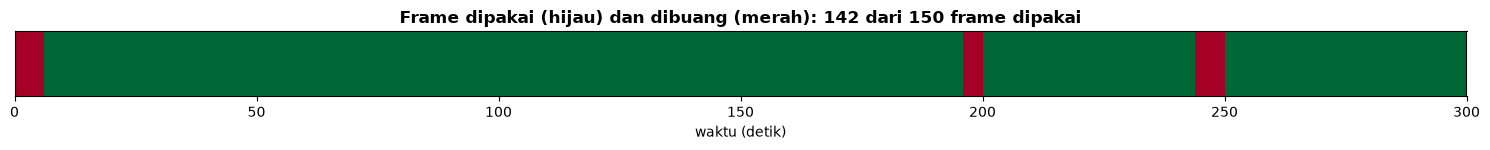

In [3]:
md_ = np.atleast_1d(scipy.io.loadmat(ROOT / r["berkas_gerak"], squeeze_me=True, struct_as_record=False)["motion_data"])
entri = {round(float(e.FD_threshold), 2): e for e in md_}[FD_AMBANG]
dipakai = np.asarray(entri.frame_removal).astype(int) == 0
assert len(dipakai) == TS["hcp2016"].shape[0]
display(pd.DataFrame({"": ["Frame total", "Frame dibuang", "Frame dipakai", "Durasi dipakai (detik)"],
                      "Nilai": [len(dipakai), int((~dipakai).sum()), int(dipakai.sum()), float(entri.remaining_seconds)]}))

fig, ax = plt.subplots(figsize=(15, 1.6))
ax.imshow(dipakai[None, :], aspect="auto", cmap="RdYlGn", vmin=0, vmax=1, extent=[0, len(dipakai) * r["TR"], 0, 1])
ax.set_yticks([]); ax.set_xlabel("waktu (detik)")
ax.set_title(f"Frame dipakai (hijau) dan dibuang (merah): {int(dipakai.sum())} dari {len(dipakai)} frame dipakai", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "21b_1_frame_dipakai.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Kovarians Ledoit-Wolf

Dari frame yang tersisa dihitung **kovarians**, yaitu seberapa searah naik-turunnya sinyal setiap pasangan parcel. Hasilnya matriks ROI × ROI (HCP: 379 × 379).

**Kenapa Ledoit-Wolf, bukan kovarians biasa?** Subjek contoh hanya punya ±140 frame, padahal atlas HCP punya 379 parcel. Kalau jumlah frame lebih sedikit dari jumlah parcel, kovarians biasa **tidak stabil**: sebagian nilai eigennya menjadi nol, sehingga matriksnya tidak bisa dipakai untuk langkah tangent (bagian 5), yang membutuhkan logaritma nilai eigen. Ledoit-Wolf "menarik" matriks sedikit ke arah matriks diagonal (*shrinkage*), dengan kekuatan yang dihitung otomatis dari data, sehingga semua nilai eigennya positif dan matriksnya stabil.

Grafik di bawah membandingkan nilai eigen kedua cara. Sel ini juga **menghitung ulang** kovarians subjek contoh dan mencocokkannya dengan `cov_<atlas>.npy`.

,,Kovarians biasa,Ledoit-Wolf
0,Nilai eigen ≈ 0 (< 1e-8 × terbesar),268,0
1,Nilai eigen terkecil,-6.58e-12,3.23e+01
2,Kekuatan shrinkage Ledoit-Wolf,-,0.074


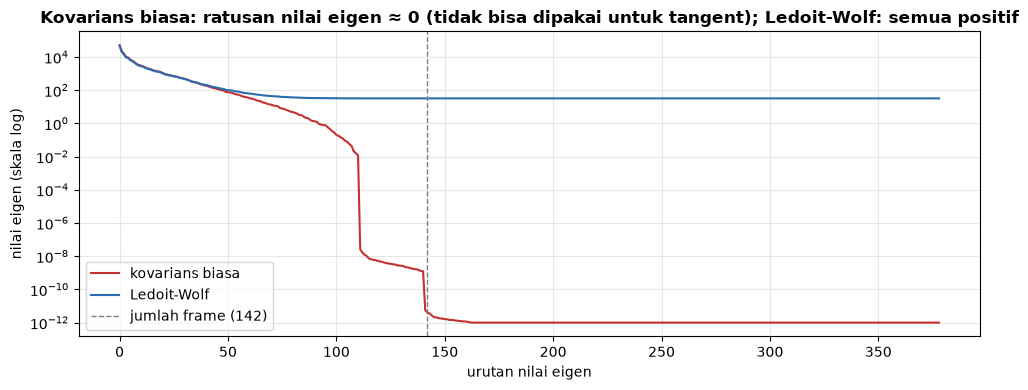

,Atlas,Selisih maksimum,Cocok
0,gordon2014,0.000000,True
1,hcp2016,0.000000,True
2,markov2012,0.000000,True


In [4]:
X = TS["hcp2016"][dipakai]
biasa = np.cov(X, rowvar=False)
lw = LedoitWolf(store_precision=False).fit(X)
eig_biasa, eig_lw = np.linalg.eigvalsh(biasa)[::-1], np.linalg.eigvalsh(lw.covariance_)[::-1]
display(pd.DataFrame({"": ["Nilai eigen ≈ 0 (< 1e-8 × terbesar)", "Nilai eigen terkecil", "Kekuatan shrinkage Ledoit-Wolf"],
                      "Kovarians biasa": [int((eig_biasa < 1e-8 * eig_biasa[0]).sum()), f"{eig_biasa[-1]:.2e}", "-"],
                      "Ledoit-Wolf": [int((eig_lw < 1e-8 * eig_lw[0]).sum()), f"{eig_lw[-1]:.2e}", f"{lw.shrinkage_:.3f}"]})
        .style.set_caption(f"HCP: {X.shape[0]} frame dipakai, {X.shape[1]} parcel"))

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(np.maximum(eig_biasa, 1e-12), label="kovarians biasa", color="#C53030")
ax.semilogy(eig_lw, label="Ledoit-Wolf", color="#2B6CB0")
ax.axvline(X.shape[0], color="gray", ls="--", lw=1, label=f"jumlah frame ({X.shape[0]})")
ax.set_xlabel("urutan nilai eigen"); ax.set_ylabel("nilai eigen (skala log)"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Kovarians biasa: ratusan nilai eigen ≈ 0 (tidak bisa dipakai untuk tangent); Ledoit-Wolf: semua positif", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "21b_2_nilai_eigen_ledoit_wolf.png", dpi=150, bbox_inches="tight")
plt.show()

cek = []
for a in ATLAS:
    hitung = LedoitWolf(store_precision=False).fit(TS[a][dipakai]).covariance_.astype(np.float32)
    simpan = np.load(FITUR / f"cov_{a}.npy", mmap_mode="r")[CONTOH]
    cek.append({"Atlas": a, "Selisih maksimum": float(np.abs(hitung - simpan).max()), "Cocok": bool(np.allclose(hitung, simpan, rtol=1e-5, atol=1e-6))})
cek = pd.DataFrame(cek)
display(cek.style.set_caption("Verifikasi: kovarians dihitung ulang vs berkas cov_<atlas>.npy (subjek contoh)"))
assert cek["Cocok"].all()

## 4. FC Korelasi (Fisher z)

Kovarians diubah menjadi **korelasi** (dibagi simpangan baku kedua parcel, sehingga nilainya −1 sampai 1), lalu ditransformasi **Fisher z** (`arctanh`) supaya sebarannya mendekati normal. Karena matriksnya simetris, yang disimpan hanya **segitiga bawah tanpa diagonal**: HCP 379 × 378 / 2 = 71.631 nilai per subjek.

FC korelasi dipakai untuk **sisi graf** (20 tetangga terkuat, S1–S3) dan **kopling struktur–fungsi** (notebook 12).

,Atlas,Nilai per subjek,Selisih maksimum,Cocok
0,gordon2014,61776,0.000000,True
1,hcp2016,71631,0.000000,True
2,markov2012,20910,0.000000,True


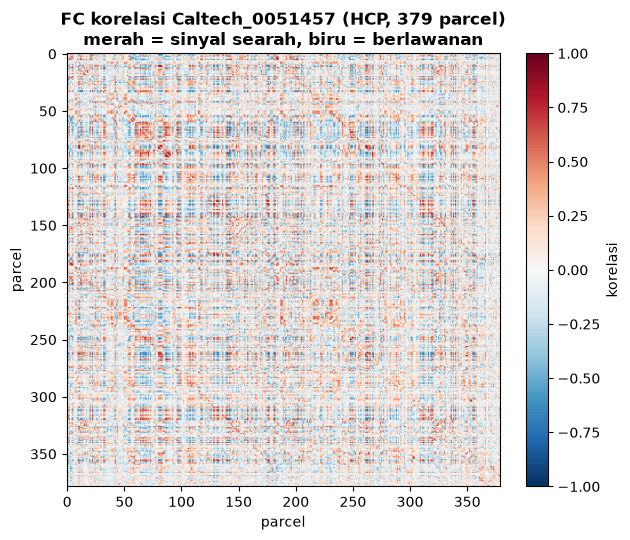

In [5]:
def korelasi_fisher(C):
    d = np.sqrt(np.diag(C))
    return np.arctanh(np.clip(sym_matrix_to_vec(C / np.outer(d, d), discard_diagonal=True), -0.999999, 0.999999)).astype(np.float32)

cek = []
for a in ATLAS:
    C = np.load(FITUR / f"cov_{a}.npy", mmap_mode="r")[CONTOH].astype(np.float64)
    hitung, simpan = korelasi_fisher(C), np.load(FITUR / f"korelasi_{a}.npy", mmap_mode="r")[CONTOH]
    cek.append({"Atlas": a, "Nilai per subjek": len(simpan), "Selisih maksimum": float(np.abs(hitung - simpan).max()),
                "Cocok": bool(np.allclose(hitung, simpan, atol=1e-5))})
cek = pd.DataFrame(cek)
display(cek.style.set_caption("Verifikasi: FC korelasi dihitung ulang vs berkas korelasi_<atlas>.npy (subjek contoh)"))
assert cek["Cocok"].all()

M_kor = segitiga_ke_matriks(np.load(FITUR / "korelasi_hcp2016.npy", mmap_mode="r")[CONTOH], 379)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(np.tanh(M_kor), cmap="RdBu_r", vmin=-1, vmax=1); plt.colorbar(im, ax=ax, fraction=0.046, label="korelasi")
ax.set_title(f"FC korelasi {r['FILE_ID']} (HCP, 379 parcel)\nmerah = sinyal searah, biru = berlawanan", fontweight="bold")
ax.set_xlabel("parcel"); ax.set_ylabel("parcel")
plt.tight_layout()
fig.savefig(FIG_DIR / "21b_3_fc_korelasi.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. FC Tangent: Membandingkan Subjek dengan "Otak Rata-rata"

Semua otak punya pola konektivitas dasar yang mirip. Contohnya, wilayah visual kiri dan kanan berkorelasi pada hampir semua orang. Pola bersama ini **tidak membedakan** ASD dari Kontrol, tetapi ikut tercampur di nilai korelasi setiap subjek.

FC tangent menghilangkan pola bersama itu:
1. **"Otak rata-rata" (acuan)** dihitung dari kovarians **subjek latih** fold tersebut, memakai rata-rata geometrik, yaitu cara merata-rata yang sesuai untuk matriks kovarians;
2. kovarians setiap subjek "dibandingkan" dengan acuan: **tangent = log( acuan^−½ · kovarians · acuan^−½ )**. Nilai 0 berarti sama dengan rata-rata; positif atau negatif berarti lebih kuat atau lebih lemah dari rata-rata;
3. hasilnya disimpan sebagai segitiga bawah, sama seperti korelasi.

**Kenapa acuan dihitung per fold?** Acuan memakai **data latih saja**. Kalau subjek uji ikut menentukan "otak rata-rata", informasi data uji bocor ke fitur. Karena itu ada 5 berkas tangent per atlas (`tangent_<atlas>_gab_0` … `_gab_4`), satu untuk setiap fold uji.

**Kenapa tangent?** Di bangku uji fitur dengan data PCP (987 subjek ABIDE I), FC tangent adalah fitur tunggal terbaik. Dengan data DCAN, tangent dan korelasi pada ABIDE I hasilnya setara (70,89% vs 71,05%, notebook 10). Tangent dipakai sebagai fitur utama karena terbukti paling kuat di bangku uji sebelumnya.

Sel berikut **menghitung ulang acuan fold 0** (HCP, dari 1.300-an subjek latih; ±2–4 menit), lalu mencocokkan tangent beberapa subjek dengan berkas yang dipakai S1–S4.

In [6]:
fold = kohort["fold_gabungan"].to_numpy()
latih0 = np.where(fold != 0)[0]
uji0 = np.where(fold == 0)[0]
COV_HCP = np.load(FITUR / "cov_hcp2016.npy", mmap_mode="r")
t0 = time.perf_counter()
acuan0 = rata_rata_geometrik(COV_HCP[latih0], max_iter=10, tol=1e-7)          # sama persis dengan notebook 22
print(f"Acuan fold 0 dihitung dari {len(latih0)} subjek latih ({time.perf_counter() - t0:.0f} detik)")

periksa = np.r_[latih0[:3], uji0[:3]]                                          # 3 subjek latih + 3 subjek uji fold 0
hitung = tangent_dari_kovarians(COV_HCP[periksa], acuan0)
simpan = np.load(FITUR / "tangent_hcp2016_gab_0.npy", mmap_mode="r")[periksa]
cek = pd.DataFrame({"Subjek": kohort["FILE_ID"].iloc[periksa].values, "Peran di fold 0": ["latih"] * 3 + ["uji"] * 3,
                    "Selisih maksimum": np.abs(hitung - simpan).max(1)})
cek["Cocok"] = cek["Selisih maksimum"] < 1e-4
display(cek.style.set_caption("Verifikasi: FC tangent dihitung ulang vs berkas tangent_hcp2016_gab_0.npy"))
assert cek["Cocok"].all()

Acuan fold 0 dihitung dari 1310 subjek latih (158 detik)


,Subjek,Peran di fold 0,Selisih maksimum,Cocok
0,Caltech_0051457,latih,0.000000,True
1,Caltech_0051459,latih,0.000000,True
2,Caltech_0051465,latih,0.000000,True
3,Caltech_0051458,uji,0.000000,True
4,Caltech_0051462,uji,0.000000,True
5,Caltech_0051463,uji,0.000000,True


**Apa yang dibuang tangent?** Untuk setiap subjek dihitung kemiripan (korelasi Pearson) antara FC-nya dan **pola FC rata-rata kelompok latih** fold 0:
- **FC korelasi** setiap subjek cukup mirip dengan pola rata-rata. Artinya, sebagian isi FC korelasi adalah pola yang dimiliki semua orang;
- **FC tangent** hampir tidak mirip lagi dengan pola rata-rata (kemiripan ≈ 0). Pola bersama sudah dibuang, dan yang tersisa adalah **ciri khas setiap subjek**. Ciri khas inilah yang dipakai model untuk membedakan ASD dan Kontrol.

,Fitur,Kemiripan dengan pola rata-rata (median),Rentang 5–95%
0,FC korelasi,0.530000,0.37 – 0.66
1,FC tangent,-0.010000,-0.11 – 0.10


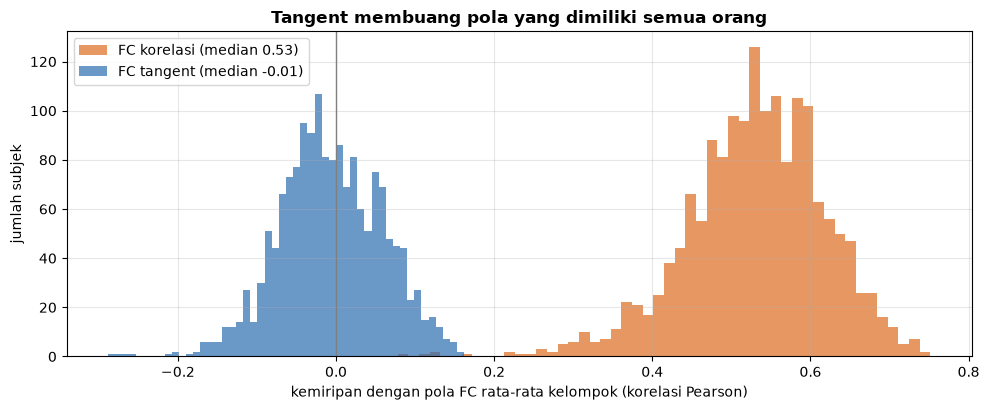

In [7]:
K_HCP = np.load(FITUR / "korelasi_hcp2016.npy", mmap_mode="r")
T_HCP = np.load(FITUR / "tangent_hcp2016_gab_0.npy", mmap_mode="r")
jumlah = np.zeros(K_HCP.shape[1])
for i in range(0, len(latih0), 256):
    jumlah += np.asarray(K_HCP[latih0[i:i + 256]], dtype=np.float64).sum(0)
pola_rata = (jumlah / len(latih0) - (jumlah / len(latih0)).mean()) / (jumlah / len(latih0)).std()

def kemiripan(V):
    hasil = []
    for i in range(0, len(V), 256):
        B = np.asarray(V[i:i + 256], dtype=np.float64)
        B = (B - B.mean(1, keepdims=True)) / B.std(1, keepdims=True)
        hasil.append(B @ pola_rata / B.shape[1])
    return np.concatenate(hasil)

r_kor, r_tan = kemiripan(K_HCP), kemiripan(T_HCP)
display(pd.DataFrame({"Fitur": ["FC korelasi", "FC tangent"], "Kemiripan dengan pola rata-rata (median)": [np.median(r_kor), np.median(r_tan)],
                      "Rentang 5–95%": [f"{np.percentile(r_kor, 5):.2f} – {np.percentile(r_kor, 95):.2f}", f"{np.percentile(r_tan, 5):.2f} – {np.percentile(r_tan, 95):.2f}"]})
        .round(2).style.set_caption(f"Kemiripan FC setiap subjek (n = {len(kohort)}) dengan pola FC rata-rata subjek latih fold 0 (HCP)"))

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(r_kor, bins=50, alpha=0.7, color="#DD6B20", label=f"FC korelasi (median {np.median(r_kor):.2f})")
ax.hist(r_tan, bins=50, alpha=0.7, color="#2B6CB0", label=f"FC tangent (median {np.median(r_tan):.2f})")
ax.axvline(0, color="gray", lw=1)
ax.set_xlabel("kemiripan dengan pola FC rata-rata kelompok (korelasi Pearson)"); ax.set_ylabel("jumlah subjek"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Tangent membuang pola yang dimiliki semua orang", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "21b_4_efek_tangent.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Pemeriksaan Seluruh Berkas FC

Tabel berikut memeriksa semua berkas FC yang dipakai tahap berikutnya: ukuran harus 1.638 subjek × jumlah pasangan parcel, dan tidak boleh ada nilai yang tidak finit (NaN/tak hingga). Berkas lain di folder yang sama (`tangent_<atlas>_a1_<k>`, `_i_ke_ii`, `_ii_ke_i`) hanya dipakai percobaan perbandingan di notebook 10 (ABIDE I saja dan lintas dataset), bukan oleh skenario S1–S4.

In [8]:
baris = []
for a, n in ATLAS.items():
    p = n * (n - 1) // 2
    for nama in ["korelasi"] + [f"tangent_gab_{k}" for k in range(5)]:
        berkas = FITUR / (f"korelasi_{a}.npy" if nama == "korelasi" else f"tangent_{a}_gab_{nama[-1]}.npy")
        V = np.load(berkas, mmap_mode="r")
        finit = all(np.isfinite(V[i:i + 256]).all() for i in range(0, len(V), 256))
        baris.append({"Atlas": a, "Berkas": berkas.name, "Bentuk": str(V.shape), "Bentuk benar": V.shape == (len(kohort), p),
                      "Semua nilai finit": finit, "Dipakai oleh": "sisi graf S1–S3, kopling (nb 23)" if nama == "korelasi" else "S1–S4, baseline LR"})
tabel = pd.DataFrame(baris)
display(tabel.style.set_caption(f"Berkas FC di {FITUR.relative_to(ROOT)}"))
assert tabel["Bentuk benar"].all() and tabel["Semua nilai finit"].all()
print(f"Jumlah fitur FC tangent per subjek (3 atlas): {sum(n * (n - 1) // 2 for n in ATLAS.values()):,}")

,Atlas,Berkas,Bentuk,Bentuk benar,Semua nilai finit,Dipakai oleh
0,gordon2014,korelasi_gordon2014.npy,"(1638, 61776)",True,True,"sisi graf S1–S3, kopling (nb 23)"
1,gordon2014,tangent_gordon2014_gab_0.npy,"(1638, 61776)",True,True,"S1–S4, baseline LR"
2,gordon2014,tangent_gordon2014_gab_1.npy,"(1638, 61776)",True,True,"S1–S4, baseline LR"
3,gordon2014,tangent_gordon2014_gab_2.npy,"(1638, 61776)",True,True,"S1–S4, baseline LR"
4,gordon2014,tangent_gordon2014_gab_3.npy,"(1638, 61776)",True,True,"S1–S4, baseline LR"
5,gordon2014,tangent_gordon2014_gab_4.npy,"(1638, 61776)",True,True,"S1–S4, baseline LR"
6,hcp2016,korelasi_hcp2016.npy,"(1638, 71631)",True,True,"sisi graf S1–S3, kopling (nb 23)"
7,hcp2016,tangent_hcp2016_gab_0.npy,"(1638, 71631)",True,True,"S1–S4, baseline LR"
8,hcp2016,tangent_hcp2016_gab_1.npy,"(1638, 71631)",True,True,"S1–S4, baseline LR"
9,hcp2016,tangent_hcp2016_gab_2.npy,"(1638, 71631)",True,True,"S1–S4, baseline LR"


Jumlah fitur FC tangent per subjek (3 atlas): 154,317


## 7. Ringkasan

| Langkah | Masukan → keluaran | Alasan |
| :--- | :--- | :--- |
| 1. *Time series* DCAN | frame × parcel, 3 atlas | sinyal per wilayah otak yang sudah dibersihkan pipeline DCAN |
| 2. Buang frame bergerak | FD ≥ 0,3 mm dibuang | gerakan kepala menimbulkan korelasi palsu |
| 3. Kovarians Ledoit-Wolf | parcel × parcel | stabil walaupun jumlah frame lebih sedikit dari jumlah parcel |
| 4. FC korelasi (Fisher z) | segitiga bawah | dipakai untuk sisi graf dan kopling struktur–fungsi |
| 5. FC tangent per fold | selisih terhadap "otak rata-rata" subjek latih | membuang pola umum yang dimiliki semua orang; acuan per fold mencegah kebocoran data uji |
| 6. Pemeriksaan | 1.638 subjek × 154.317 nilai (3 atlas) | semua berkas lengkap dan finit |

Semua hasil yang dihitung ulang di notebook ini **identik** dengan berkas yang dipakai skenario S1–S4.

**Langkah berikutnya:** notebook 12 mengolah sMRI (permukaan korteks) menjadi morfometri, MIND, dan kopling struktur–fungsi.